# Лабораторная работа № 3. Виртуальный анализ 3D-модели робототехнического узла и подготовка к аддитивному производству


**Объект исследования:** детали манипулятора SO-101 из репозитория курса [`robotics-course`](https://github.com/BosenkoTM/robotics-course/tree/2026/06-simulation-and-sim2real/seminar/so101) — тех же, что описаны в URDF робота и используются на занятиях по симуляции.

**Цель:** по готовой STL-модели робототехнического узла оценить её пригодность к печати, выбрать ориентацию и параметры FDM/FFF-печати и обосновать выбор расчётами — без физического принтера.

> **Версия студента.** Заполните ячейки с пометкой `# TODO` (правила — ниже). После каждого шага запустите ячейку **самопроверки** и заполните блок **«Что получили и что это значит»**: 2–4 предложения с вашими числами. Перед сдачей выполните `Runtime → Restart and run all` (Colab) или `Kernel → Restart & Run All` (Jupyter).

**Что сдать:** ссылку на **собственный репозиторий** на GitHub или GitVerse, в котором лежат `lab_03_student.ipynb` с выполненными ячейками, файл `print_map_variant_XX.csv` и заполненный `README.md` (состав и шаблон — в описании работы `lab_03.md`, раздел «Что предоставить»). На платформу загружается только ссылка. Физическая печать не требуется.

### Как заполнять ячейки с TODO

| Что видите в ячейке | Что сделать |
|---|---|
| `...` (три точки) | это **пустое место**: сотрите три точки и впишите код |
| `# ← впишите: len(raw.faces)` | справа после стрелки — **что именно** вписать вместо `...` (можно скопировать) |
| `# ← словами: …` | подсказка словами — код нужно составить самостоятельно по формуле из теории |
| строки, начинающиеся с `# ` под пометкой «уберите #» | выделите эти строки и нажмите **Ctrl + /** — знак `#` исчезнет, строки станут кодом |
| ячейка «Самопроверка шага N» | ничего не меняйте, просто запустите: `Шаг N: ок` — всё верно |

**Порядок работы:** заполнили TODO → запустили ячейку (**Shift + Enter**) → запустили самопроверку → записали вывод.

**Если появилось сообщение об ошибке:**

* `Не заполнено: …` — в ячейке осталось `...`; в сообщении указано, какое поле и где;
* `NameError: name '…' is not defined` — не запущена одна из **предыдущих** ячеек: выполните `Runtime → Run before` (Colab) и повторите;
* после исправления TODO **перезапустите все ячейки ниже** — они используют результат этой ячейки.

Названия переменных, функций и ключей таблиц не меняйте: от них зависят следующие шаги и самопроверки.

## 1. Теоретический блок

### 1.1. Где эта работа в цифровом маршруте детали

```
CAD-модель → STL/3MF → ПРОВЕРКА СЕТКИ → ОРИЕНТАЦИЯ → ПАРАМЕТРЫ ПЕЧАТИ → слайсер → G-code → печать → постобработка → контроль
                       └──────────── эта лабораторная работа (виртуально) ────────────┘
```

Ошибка, допущенная на ранних шагах, переносится дальше: незамкнутую сетку слайсер «залатает» по-своему, неверная ориентация даст лишние поддержки и слабую деталь, а масштаб «на глаз» сломает посадку сервопривода. Поэтому инженер сначала **анализирует модель**, и только потом нажимает Print.

### 1.2. Формат STL: что в нём есть и чего нет

STL описывает поверхность тела набором треугольников. Для каждого треугольника хранятся три вершины и нормаль.

| Что есть в STL | Чего в STL **нет** |
|---|---|
| координаты вершин треугольников | единиц измерения |
| нормали граней | цвета, материала, допусков |
| (в ASCII) имя тела | параметрической истории модели |

* **ASCII-STL** — текст (`solid … facet normal … vertex …`), удобен для чтения, но объёмен.
* **Binary-STL** — 80 байт заголовка + 4 байта числа граней + 50 байт на грань: $S = 84 + 50\,F$ байт.
* **Единицы.** Для печати принято считать числа миллиметрами. В робототехнике (URDF, ROS, REP 103) модели часто хранят **в метрах** — деталь 50 мм превратится в слайсере в «пылинку» 0,05 мм. Единицы нужно **проверять по габаритам**.
* **3MF** хранит единицы, несколько тел, цвета и параметры печати. Для сложных проектов он предпочтительнее STL.

### 1.3. Качество сетки: почему `is_watertight` важнее, чем кажется

* **Замкнутость (watertight, manifold).** Каждое ребро принадлежит ровно двум треугольникам, поверхность не имеет «дыр».
* **Согласованность нормалей (winding).** Все нормали смотрят наружу.
* **Тела (shells).** Связные куски сетки. В одном STL их может оказаться несколько: деталь, вспомогательная геометрия (модель камеры, винта), «мусорные» треугольники после экспорта.

Объём сетки считается по теореме Гаусса–Остроградского как сумма знаковых объёмов тетраэдров «начало координат — треугольник»:

$$V=\frac16\sum_{i=1}^{F}\mathbf v_{1,i}\cdot(\mathbf v_{2,i}\times\mathbf v_{3,i}).$$

Формула верна **только для замкнутой согласованной поверхности**. Для незамкнутой сетки `mesh.volume` — число без физического смысла, и масса, время и стоимость, посчитанные по нему, тоже окажутся неверными. Для одного замкнутого тела рода $g$ (число «сквозных отверстий») выполняется формула Эйлера: $\chi = V - E + F = 2 - 2g$.

### 1.4. Геометрические характеристики

| Величина | Обозначение | Зачем инженеру печати |
|---|---|---|
| Габариты (AABB) | $L_x, L_y, L_z$ | поместится ли деталь на стол; высота → число слоёв |
| Площадь поверхности | $A$ | объём оболочек (периметров) |
| Объём | $V$ | расход материала, масса, время |
| Коэффициент заполнения габарита | $k = V / (L_x L_y L_z)$ | «ажурность» детали |
| Тонкостенность | $A/V$, мм⁻¹ | чем больше, тем большую долю массы дают оболочки, а не заполнение |
| Центр масс | $\mathbf c$ | устойчивость на столе |

### 1.5. Ориентация детали на столе

Ориентация — **конструкторское решение**, а не настройка «по умолчанию». Она определяет:

1. **Высоту $H$** → число слоёв $N=\lceil H/h\rceil$ → время печати.
2. **Площадь контакта со столом** → адгезию и риск отрыва или коробления (особенно ABS).
3. **Нависания.** Грань с нормалью $\mathbf n$ требует поддержки, если она обращена вниз круче критического угла (обычно 45° от вертикали): $n_z < -\cos 45^\circ \approx -0{,}707$. Оценка объёма поддержек: $V_{sup}\approx\sum_i A_i\,|n_{z,i}|\,z_i$ (проекция грани на стол × высота грани над столом).
4. **Анизотропию прочности.** Прочность между слоями (по оси Z) заметно ниже, чем вдоль слоя. Основные нагрузки (изгиб плеча манипулятора, затяжка винта) должны идти **вдоль слоёв**, а не отрывать их друг от друга.
5. **Качество поверхности.** «Ступеньки» слоёв сильнее видны на поверхностях, почти параллельных столу.

### 1.6. Высота слоя, производительность и время

* Число слоёв: $N=\lceil H/h\rceil$. При уменьшении $h$ вдвое слоёв вдвое больше.
* Практическое ограничение: $h \le 0{,}75\,d_{сопла}$ (для сопла 0,4 мм — до 0,3 мм).
* Объёмная производительность (формула из лекции 3): $Q = w\,h\,v$, мм³/с. Здесь $w\approx1{,}125\,d$ — ширина экструзии, $v$ — скорость печати.
* Время печати (оценка снизу, без холостых перемещений и ускорений): $t \approx V_{extr}/Q$.

### 1.7. Масса: оболочка + заполнение

Деталь печатается как оболочка из $n_w$ периметров и верхних/нижних слоёв плюс разреженное заполнение с долей $\varphi$:

$$V_{shell}\approx\min\left(V,\;A\cdot n_w\cdot w\right),\qquad V_{extr}=V_{shell}+\varphi\,(V-V_{shell}),$$

$$m=\rho\,\bigl(V_{extr}+\varphi_s V_{sup}\bigr).$$

Здесь $\varphi_s \approx 0{,}15$ — плотность поддержек. Отсюда важный вывод: у тонкостенных деталей (большое $A/V$) **заполнение мало влияет на массу**, потому что основную массу дают периметры.

### 1.8. Масштабирование и посадки

$L\propto s,\;A\propto s^2,\;V\propto s^3$. Масса растёт **медленнее**, чем $s^3$: толщина оболочки $n_w w$ от масштаба не зависит, поэтому объём оболочек растёт как $s^2$, и только заполнение — как $s^3$. Изменение посадочного размера $D$: $\Delta = D\,(s-1)$. Типичная точность бытового FDM-принтера — порядка ±0,2 мм. Значит, сервопривод STS3215 (корпус 24,8 мм) перестанет входить в посадочное место уже при $s=0{,}99$: $\Delta=-0{,}25$ мм. **Функциональные детали робота не масштабируют**. Масштаб допустим только для демонстрационных макетов или при одновременном пересчёте всех сопрягаемых деталей.

### 1.9. Материалы (типичные паспортные значения; уточняйте по паспорту своей катушки)

| Материал | ρ, г/см³ | T сопла, °C | T стола, °C | Скорость (учебный профиль), мм/с | Теплостойкость | Особенности для робототехники |
|---|---|---|---|---|---|---|
| PLA | 1,24 | 190–220 | 50–60 | 50 | ≈ 55 °C | прост в печати, жёсткий, хрупкий, размягчается у нагретого сервопривода |
| PETG | 1,27 | 220–250 | 70–85 | 40 | ≈ 70 °C | вязкий, ударостойкий, хороший выбор для силовых узлов |
| ABS | 1,04 | 230–260 | 90–110 | 45 | ≈ 95 °C | теплостойкий, сильная усадка и коробление, нужна закрытая камера и вытяжка |
| TPU | 1,20 | 210–235 | 30–60 | 20 | — | гибкий: накладки губок захвата, демпферы; не подходит для несущих деталей |

## 2. Варианты заданий

Номер варианта выдаёт преподаватель. Деталь, материал и режим подставятся автоматически после того, как вы укажете `VARIANT`.

| № | Деталь SO-101 (файл в `assets/`) | Материал | Слой h, мм | Заполнение, % | Сопло, мм | Масштаб s для анализа | Исследовательский фокус |
|---:|---|---|---:|---:|---:|---:|---|
| 1 | `base_so101_v2` — основание | PLA | 0.20 | 20 | 0.4 | 0.97 | Крупная деталь: поместится ли на стол 200×200×200 мм, сколько часов печати |
| 2 | `base_motor_holder_so101_v1` — держатель привода основания | PETG | 0.16 | 25 | 0.4 | 0.98 | Посадка сервопривода STS3215 при масштабе s |
| 3 | `motor_holder_so101_base_v1` — держатель привода | PLA | 0.12 | 30 | 0.4 | 1.02 | Модель из нескольких тел: что печатать и как это меняет объём |
| 4 | `motor_holder_so101_wrist_v1` — держатель привода запястья | ABS | 0.16 | 30 | 0.4 | 0.97 | ABS: ориентация с учётом коробления и площади контакта |
| 5 | `moving_jaw_so101_v1` — подвижная губка захвата | TPU | 0.20 | 20 | 0.4 | 1.03 | Пригоден ли TPU для губки целиком или только для накладки |
| 6 | `rotation_pitch_so101_v1` — узел поворота | PETG | 0.24 | 20 | 0.6 | 0.95 | Сопло 0,6 мм: выигрыш во времени и цена в качестве |
| 7 | `under_arm_so101_v1` — нижнее плечо | PLA | 0.20 | 15 | 0.4 | 1.05 | Длинная балка: ориентация и анизотропия при изгибе |
| 8 | `upper_arm_so101_v1` — верхнее плечо | PETG | 0.20 | 20 | 0.6 | 0.96 | Длинная балка + сопло 0,6 мм: время и прочность |
| 9 | `waveshare_mounting_plate_so101_v2` — монтажная плата | PLA | 0.12 | 40 | 0.4 | 1.04 | Плоская деталь: доля оболочек в массе, смысл заполнения |
| 10 | `wrist_roll_follower_so101_v1` — звено запястья | ABS | 0.20 | 25 | 0.4 | 0.98 | Сравнение с разобранным примером (крепление камеры) |
| 11 | `wrist_roll_pitch_so101_v2` — звено наклона запястья | PETG | 0.16 | 25 | 0.4 | 1.02 | Длина звена при масштабе и нависания |
| 12 | `base_so101_v2` — основание | PETG | 0.28 | 15 | 0.6 | 1.03 | Быстрая печать крупной детали: время против качества |
| 13 | `base_motor_holder_so101_v1` — держатель привода основания | ABS | 0.20 | 30 | 0.4 | 0.96 | ABS + посадка привода: усадка и масштаб |
| 14 | `motor_holder_so101_base_v1` — держатель привода | PETG | 0.16 | 20 | 0.4 | 0.95 | Модель из нескольких тел + посадка привода |
| 15 | `motor_holder_so101_wrist_v1` — держатель привода запястья | PLA | 0.24 | 15 | 0.6 | 1.05 | Сопло 0,6 мм на мелкой детали: оправдано ли |
| 16 | `moving_jaw_so101_v1` — подвижная губка захвата | PLA | 0.12 | 40 | 0.4 | 0.97 | Губка из PLA: ориентация пальца относительно слоёв |
| 17 | `rotation_pitch_so101_v1` — узел поворота | ABS | 0.16 | 30 | 0.4 | 1.04 | ABS: ориентация и площадь контакта |
| 18 | `under_arm_so101_v1` — нижнее плечо | PETG | 0.24 | 20 | 0.6 | 0.98 | Длинная балка: время при сопле 0,6 мм |
| 19 | `upper_arm_so101_v1` — верхнее плечо | PLA | 0.16 | 25 | 0.4 | 1.02 | Длинная балка: анизотропия и поддержки |
| 20 | `waveshare_mounting_plate_so101_v2` — монтажная плата | PETG | 0.20 | 50 | 0.4 | 0.96 | Плоская деталь: число слоёв и выбор h |
| 21 | `wrist_roll_follower_so101_v1` — звено запястья | PLA | 0.28 | 15 | 0.6 | 1.05 | Сравнение с разобранным примером при быстрой печати |
| 22 | `wrist_roll_pitch_so101_v2` — звено наклона запястья | ABS | 0.24 | 20 | 0.6 | 0.97 | ABS + сопло 0,6 мм |
| 23 | `base_so101_v2` — основание | ABS | 0.24 | 15 | 0.6 | 1.02 | ABS на крупной детали: коробление и закрытая камера |
| 24 | `under_arm_so101_v1` — нижнее плечо | PLA | 0.12 | 30 | 0.4 | 0.95 | Тонкий слой на длинной детали: число слоёв и время |
| 25 | `moving_jaw_so101_v1` — подвижная губка захвата | PETG | 0.16 | 25 | 0.4 | 1.04 | Губка из PETG: ориентация и нависания |

## Критерии оценивания (максимум 20 баллов)

| № | Критерий | Баллы | Полный балл ставится, если… |
|---:|---|---:|---|
| 1 | Загрузка и диагностика модели | 3 | выведены габариты, площадь, объём, `is_watertight`, число тел; проверены единицы; объяснено, можно ли доверять «сырому» объёму |
| 2 | Подготовка печатного тела и его характеристики | 2 | выделено печатное тело, посчитаны V, A, k, A/V; указана ошибка «сырого» объёма в % (или обосновано её отсутствие) |
| 3 | Сравнение ориентаций и выбор | 4 | сравнено ≥ 3 ориентаций (включая заданную вариантом) по H, N, контакту, нависаниям и поддержкам; выбор обоснован с учётом анизотропии и назначения детали |
| 4 | Слои и время печати | 2 | рассчитаны N и t по формуле Q = w·h·v для своего h и ещё ≥ 2 значений h; есть график и вывод о компромиссе «время — качество» |
| 5 | Масса и материал | 3 | масса посчитана по модели «оболочка + заполнение»; сравнены материалы; оценена пригодность заданного материала для этой детали |
| 6 | Масштаб и посадки | 2 | показано, как меняются V (∝ s³) и масса; рассчитано Δ посадочного размера при заданном s; сделан вывод, можно ли масштабировать деталь |
| 7 | Виртуальный слайс | 1 | построены сечения и профиль площади слоёв; объём по слоям сверен с объёмом сетки (расхождение < 1 %) |
| 8 | Карта параметров печати | 1 | карта заполнена полностью, CSV-файл есть в репозитории |
| 9 | Аналитический вывод | 2 | вывод опирается на собственные числа (не общие фразы), содержит рекомендацию и ограничения модели расчёта; ключевые числа и вывод перенесены в `README.md` репозитория |
| | **Итого** | **20** | |

**Шкала:** 18–20 — «отлично», 14–17 — «хорошо», 10–13 — «удовлетворительно», менее 10 — работа возвращается на доработку.

**Снижение баллов:** выводы без чисел — до −2; объём незамкнутой сетки принят без проверки — критерий 1 не более 1 балла; не проверены единицы (масса в микрограммах или тоннах) — критерий 1 не более 1 балла; код не запускается «сверху вниз» после `Restart & Run All` или тетрадка сохранена без результатов выполнения — до −3; `README.md` не заполнен по шаблону — до −1.

**Условие приёма:** ссылка на репозиторий открывается, в нём есть тетрадка с результатами, CSV-файл и заполненный `README.md`.

## 3. Ход работы

### Шаг 0. Окружение и параметры варианта

**Зачем.** Все исходные данные задаются в одном месте, поэтому расчёт воспроизводим. Ячейки этого шага уже готовы: укажите только номер варианта (**TODO-0**) и запустите все ячейки шага по порядку.

In [1]:
import importlib, subprocess, sys
for pkg in ["trimesh", "shapely"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import math, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import trimesh

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)

# Единый стиль графиков: тонкие линии, приглушённая сетка, фиксированные цвета
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
})
C_MODEL, C_WARN, C_OK, C_ALT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAT_COLORS = {"PLA": "#2a78d6", "PETG": "#eb6834", "ABS": "#1baf7a", "TPU": "#eda100"}
print("trimesh", trimesh.__version__)

trimesh 5.2.0


In [2]:
RAW = "https://raw.githubusercontent.com/BosenkoTM/robotics-course/2026/"
CAM_STL = RAW + "06-simulation-and-sim2real/seminar/so101/Wrist_Cam_Mount_32x32_UVC_Module_SO101.stl"
ASSETS = RAW + "01-intro-and-kinematics/assets/urdf/so101/assets/"

# Варианты заданий: деталь, материал, слой, заполнение, сопло, масштаб для анализа, фокус
VARIANTS = pd.DataFrame([
    (1,  "base_so101_v2",                     "PLA",  0.20, 20, 0.4, 0.97, "крупная деталь: стол и время"),
    (2,  "base_motor_holder_so101_v1",        "PETG", 0.16, 25, 0.4, 0.98, "посадка сервопривода"),
    (3,  "motor_holder_so101_base_v1",        "PLA",  0.12, 30, 0.4, 1.02, "несколько тел в STL"),
    (4,  "motor_holder_so101_wrist_v1",       "ABS",  0.16, 30, 0.4, 0.97, "ABS: коробление и контакт"),
    (5,  "moving_jaw_so101_v1",               "TPU",  0.20, 20, 0.4, 1.03, "пригодность TPU"),
    (6,  "rotation_pitch_so101_v1",           "PETG", 0.24, 20, 0.6, 0.95, "сопло 0,6 мм"),
    (7,  "under_arm_so101_v1",                "PLA",  0.20, 15, 0.4, 1.05, "балка: анизотропия"),
    (8,  "upper_arm_so101_v1",                "PETG", 0.20, 20, 0.6, 0.96, "балка + сопло 0,6"),
    (9,  "waveshare_mounting_plate_so101_v2", "PLA",  0.12, 40, 0.4, 1.04, "плоская деталь: оболочки"),
    (10, "wrist_roll_follower_so101_v1",      "ABS",  0.20, 25, 0.4, 0.98, "сравнение с примером"),
    (11, "wrist_roll_pitch_so101_v2",         "PETG", 0.16, 25, 0.4, 1.02, "длина звена и нависания"),
    (12, "base_so101_v2",                     "PETG", 0.28, 15, 0.6, 1.03, "быстрая печать"),
    (13, "base_motor_holder_so101_v1",        "ABS",  0.20, 30, 0.4, 0.96, "ABS + посадка"),
    (14, "motor_holder_so101_base_v1",        "PETG", 0.16, 20, 0.4, 0.95, "несколько тел + посадка"),
    (15, "motor_holder_so101_wrist_v1",       "PLA",  0.24, 15, 0.6, 1.05, "сопло 0,6 на мелкой детали"),
    (16, "moving_jaw_so101_v1",               "PLA",  0.12, 40, 0.4, 0.97, "губка: слои и палец"),
    (17, "rotation_pitch_so101_v1",           "ABS",  0.16, 30, 0.4, 1.04, "ABS: ориентация"),
    (18, "under_arm_so101_v1",                "PETG", 0.24, 20, 0.6, 0.98, "балка: время"),
    (19, "upper_arm_so101_v1",                "PLA",  0.16, 25, 0.4, 1.02, "балка: поддержки"),
    (20, "waveshare_mounting_plate_so101_v2", "PETG", 0.20, 50, 0.4, 0.96, "плоская деталь: выбор h"),
    (21, "wrist_roll_follower_so101_v1",      "PLA",  0.28, 15, 0.6, 1.05, "пример + быстрая печать"),
    (22, "wrist_roll_pitch_so101_v2",         "ABS",  0.24, 20, 0.6, 0.97, "ABS + сопло 0,6"),
    (23, "base_so101_v2",                     "ABS",  0.24, 15, 0.6, 1.02, "ABS на крупной детали"),
    (24, "under_arm_so101_v1",                "PLA",  0.12, 30, 0.4, 0.95, "тонкий слой, длинная деталь"),
    (25, "moving_jaw_so101_v1",               "PETG", 0.16, 25, 0.4, 1.04, "губка PETG: нависания"),
], columns=["variant", "part", "material", "layer_mm", "infill_pct", "nozzle_mm", "scale", "focus"]).set_index("variant")

# Справочник материалов (типичные паспортные значения; учебный профиль скорости)
MATERIALS = pd.DataFrame({
    "density_g_cm3": {"PLA": 1.24, "PETG": 1.27, "ABS": 1.04, "TPU": 1.20},
    "t_nozzle":      {"PLA": "190–220", "PETG": "220–250", "ABS": "230–260", "TPU": "210–235"},
    "t_bed":         {"PLA": "50–60", "PETG": "70–85", "ABS": "90–110", "TPU": "30–60"},
    "speed_mm_s":    {"PLA": 50, "PETG": 40, "ABS": 45, "TPU": 20},
    "heat_C":        {"PLA": 55, "PETG": 70, "ABS": 95, "TPU": None},
})

# Посадочные размеры, по которым проверяем масштаб
SERVO_PARTS = {"base_motor_holder_so101_v1", "motor_holder_so101_base_v1", "motor_holder_so101_wrist_v1"}
FIT_DIMS = {"camera": "посадочное место модуля камеры 32×32 мм",
            "servo":  "посадочное место корпуса сервопривода STS3215 (24,8 мм)",
            "link":   "наибольший габарит звена (межосевые расстояния в URDF)"}
FIT_SIZE = {"camera": 32.0, "servo": 24.8}

# Принтер и профиль (учебное допущение — уточните по своему принтеру)
BED_MM = (200, 200, 200)     # рабочая область X×Y×Z
WALLS = 2                    # число периметров
SUPPORT_DENSITY = 0.15       # плотность поддержек
OVERHANG_DEG = 45            # критический угол нависания

In [3]:
# TODO-0. Номер вашего варианта (выдаёт преподаватель)
VARIANT = 7   # ← впишите номер вместо None, например: VARIANT = 7
assert VARIANT is not None, "TODO-0: впишите номер варианта вместо None, например VARIANT = 7"
assert 1 <= VARIANT <= 25, "Номер варианта — целое число от 1 до 25"

In [4]:
def get_config(variant):
    """Параметры варианта; 0 — разобранный пример (крепление камеры)."""
    if variant == 0:
        row = dict(part="Wrist_Cam_Mount_32x32_UVC_Module_SO101", material="PETG", layer_mm=0.20,
                   infill_pct=20, nozzle_mm=0.4, scale=0.95, focus="разобранный пример", url=CAM_STL, fit="camera")
    else:
        row = VARIANTS.loc[variant].to_dict()
        row["url"] = ASSETS + row["part"] + ".stl"
        row["fit"] = "servo" if row["part"] in SERVO_PARTS else "link"
    row["density"] = MATERIALS.loc[row["material"], "density_g_cm3"]
    row["speed"] = MATERIALS.loc[row["material"], "speed_mm_s"]
    row["line_w"] = round(1.125 * row["nozzle_mm"], 3)   # ширина экструзии
    return row

cfg = get_config(VARIANT)
pd.Series(cfg).to_frame("значение")

,значение
part,under_arm_so101_v1
material,PLA
layer_mm,0.2
infill_pct,15
nozzle_mm,0.4
scale,1.05
focus,балка: анизотропия
url,https://raw.githubusercontent.com/BosenkoTM/ro...
fit,link
density,1.24


In [5]:
def download(url, folder="stl"):
    Path(folder).mkdir(exist_ok=True)
    path = Path(folder) / url.split("/")[-1]
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

stl_path = download(cfg["url"])
print(stl_path, f"{stl_path.stat().st_size/1e6:.2f} МБ")
with open(stl_path, "rb") as f:
    head = f.read(80)
print("Тип файла:", "ASCII-STL" if head.lstrip().lower().startswith(b"solid") else "binary-STL")

stl/under_arm_so101_v1.stl 1.98 МБ
Тип файла: binary-STL


In [6]:
# Служебные функции: проверка заполнения TODO и отрисовка 3D-модели. Эту ячейку не меняйте.

def check_filled(where, values):
    """Проверяет, что вместо «...» вписан код. Если нет — сообщает, какое поле не заполнено."""
    empty = [name for name, v in values.items() if v is ...]
    if empty:
        raise ValueError(f"Не заполнено ({where}): " + ", ".join(empty)
                         + ". Замените «...» на код из подсказки «← впишите:» в этой строке.")


def plot_mesh(ax, mesh, color=C_MODEL, highlight=None, hl_color=C_WARN, title=""):
    """Рисует сетку с простым затенением; highlight — маска граней для выделения."""
    light = np.array([0.4, -0.5, 0.75]); light /= np.linalg.norm(light)
    shade = 0.45 + 0.55 * np.clip(mesh.face_normals @ light, 0, 1)
    base = np.array(plt.matplotlib.colors.to_rgb(color))
    fc = np.outer(shade, base) + (1 - shade)[:, None] * 0.92
    if highlight is not None:
        fc[highlight] = plt.matplotlib.colors.to_rgb(hl_color)
    ax.add_collection3d(Poly3DCollection(mesh.triangles, facecolors=np.clip(fc, 0, 1), linewidths=0))
    lo, hi = mesh.bounds
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(np.maximum(hi - lo, 1e-6))
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
    ax.set_title(title, fontsize=9)
    ax.tick_params(labelsize=7)

### Шаг 1. Загрузка модели и первичная проверка

**Зачем.** STL не хранит единиц, а `mesh.volume` имеет смысл только для замкнутой сетки. Прежде чем считать массу и время, нужно ответить: в каких единицах файл, замкнута ли сетка, сколько в ней тел.

**Что сделать.**

1. **TODO-1.1 — проверка единиц.** В функции `load_stl_mm` найдите три строки под пометкой «уберите #», выделите их и нажмите **Ctrl + /**. Смысл: если самый большой габарит детали меньше 1, значит, файл записан в **метрах**, и его нужно умножить на 1000.
2. **TODO-1.2 — таблица `raw_info`.** Вместо каждого `...` впишите выражение, указанное справа после `← впишите:`. Объект `raw` — это загруженная сетка; у неё есть готовые свойства:

| Свойство | Что означает |
|---|---|
| `raw.faces` | список треугольников; `len(raw.faces)` — их число $F$ |
| `raw.extents` | габариты $L_x, L_y, L_z$, мм |
| `raw.area` | площадь поверхности $A$, мм² |
| `raw.volume` | объём, мм³ (имеет смысл только для замкнутой сетки) |
| `raw.is_watertight` | `True`, если сетка замкнута |

3. Запустите ячейку, затем ячейку самопроверки.

**Контрольная точка:** наибольший габарит вашей детали — от 5 до 200 мм. Если габарит меньше 1 — не выполнен TODO-1.1.

In [9]:
def load_stl_mm(path):
    """Загружает STL и приводит к миллиметрам."""
    mesh = trimesh.load_mesh(path)
    unit = "мм"
    # TODO-1.1. Уберите # в трёх строках ниже: выделите их и нажмите Ctrl + /
    if mesh.extents.max() < 1.0:           # самый большой габарит меньше 1 → файл в метрах
        mesh.apply_scale(1000.0)           # переводим метры в миллиметры
        unit = "м → пересчитано в мм (×1000)"
    return mesh, unit


raw, unit = load_stl_mm(stl_path)

# TODO-1.2. Вместо каждого «...» впишите выражение после стрелки
raw_info = pd.Series({
    "единицы исходного файла": unit,                    # готово
    "граней F": len(raw.faces),                                    # ← впишите: len(raw.faces)
    "габариты Lx×Ly×Lz, мм": " × ".join(f"{v:.1f}" for v in raw.extents),                       # ← впишите: " × ".join(f"{v:.1f}" for v in raw.extents)
    "площадь A, мм²": round(raw.area, 1),                              # ← впишите: round(raw.area, 1)
    "объём mesh.volume, мм³": round(raw.volume, 1),                      # ← впишите: round(raw.volume, 1)
    "is_watertight": raw.is_watertight,                               # ← впишите: raw.is_watertight
    "число тел (shells)": len(raw.split(only_watertight=False)),                          # ← впишите: len(raw.split(only_watertight=False))
    "размер binary-STL, МБ (84+50F)": round((84 + 50 * 39516) / 1000000, 2)             # ← словами: (84 + 50 · число граней) / 1 000 000, округлить до 0,01
})
check_filled("TODO-1.2, таблица raw_info", raw_info.to_dict())
raw_info.to_frame("исходная модель")

,исходная модель
единицы исходного файла,м → пересчитано в мм (×1000)
граней F,39516
"габариты Lx×Ly×Lz, мм",130.7 × 24.0 × 64.4
"площадь A, мм²",22686.4
"объём mesh.volume, мм³",92949.1
is_watertight,True
число тел (shells),1
"размер binary-STL, МБ (84+50F)",1.98


In [10]:
# Самопроверка шага 1 (ничего не меняйте — просто запустите)
assert 5 < raw.extents.max() < 300, (f"Наибольший габарит {raw.extents.max():.3f} — вне диапазона 5…300 мм. "
                                     "Скорее всего, файл в метрах: выполните TODO-1.1 и перезапустите ячейку выше")
assert not any(v is ... for v in raw_info.values), "Заполните все поля raw_info (TODO-1.2)"
assert raw_info["граней F"] == len(raw.faces), "«граней F» должно быть равно len(raw.faces)"
print("Шаг 1: ок")

Шаг 1: ок


**✍️ Что получили и что это значит.** В каких единицах был файл? Замкнута ли сетка, сколько тел? Можно ли доверять `mesh.volume` и почему?

*Ваш ответ:* Файл был записан в метрах: наибольший габарит до пересчёта был 0,1307 < 1, поэтому load_stl_mm умножил координаты на 1000, и деталь получила реальный размер 130,7 × 24,0 × 64,4 мм (без этой проверки слайсер увидел бы «пылинку» 0,13 мм). Сетка замкнута (is_watertight = True), тело одно, F = 39 516 граней, A = 22 686,4 мм², V = 92 949,1 мм³. Формат binary-STL подтверждён размером: 84 + 50·39 516 = 1,98 МБ — ровно столько весит скачанный файл. Поскольку поверхность замкнута и согласована, mesh.volume посчитан по теореме Гаусса–Остроградского корректно и ему можно доверять; окончательно это подтвердит шаг 2.

### Шаг 2. Диагностика тел и выделение печатного тела

**Зачем.** В STL могут лежать вспомогательная геометрия, мусор экспорта или внутренние полости. Печатать и считать нужно только деталь.

**Что сделать.**

1. Запустите ячейку с таблицей тел (она готова) и посмотрите: сколько тел, какие из них замкнуты.
2. **TODO-2.1.** В функции `select_printable` выберите главное тело: из списка замкнутых тел `closed` — то, у которого **наибольший объём**.
3. **TODO-2.2.** Найдите внутренние полости: замкнутые тела с **отрицательным** объёмом, которые целиком лежат внутри главного тела (их габаритный ящик внутри ящика `[lo, hi]`). Их объём вычтется автоматически.
4. **TODO-2.3.** Посчитайте ошибку «сырого» объёма в процентах:

$$err = \frac{V_{сырой} - V_{тела}}{V_{тела}}\cdot 100\,\%.$$

Если в файле одно замкнутое тело, ошибка равна 0 % — это нормальный результат.

**Контрольная точка:** `body.is_watertight == True`, $V > 0$.

In [11]:
def bodies_table(mesh):
    """Таблица тел сетки: сколько граней, замкнуто ли, объём, габариты."""
    parts = mesh.split(only_watertight=False)
    rows = []
    for i, p in enumerate(parts):
        rows.append(dict(body=i, faces=len(p.faces), watertight=p.is_watertight,
                         volume_mm3=abs(p.volume) if p.is_watertight else np.nan,
                         area_mm2=p.area, Lx=p.extents[0], Ly=p.extents[1], Lz=p.extents[2]))
    return parts, pd.DataFrame(rows).sort_values("faces", ascending=False).reset_index(drop=True)

parts, bodies = bodies_table(raw)
kind = np.where(bodies.watertight, "замкнутое тело",
        np.where(bodies.faces == 1, "одиночный треугольник", "незамкнутая оболочка"))
summary = bodies.assign(kind=kind).groupby("kind").agg(
    тел=("body", "size"), граней=("faces", "sum"), площадь_мм2=("area_mm2", "sum"))
display(summary)
bodies.head(5)

,тел,граней,площадь_мм2
kind,,,
замкнутое тело,1,39516,22686.37


,body,faces,watertight,volume_mm3,area_mm2,Lx,Ly,Lz
0,0,39516,True,92949.1,22686.37,130.7,24.0,64.4


In [12]:
def select_printable(mesh):
    parts = mesh.split(only_watertight=False)                       # все тела файла
    closed = [p for p in parts if p.is_watertight and p.volume > 0]  # замкнутые тела с V > 0
    main = max(closed, key=lambda p: p.volume)        # TODO-2.1 ← впишите: max(closed, key=lambda p: p.volume)
    check_filled("TODO-2.1, select_printable", {"main": main})
    lo, hi = main.bounds                                            # углы габаритного ящика главного тела
    cavities = [p for p in parts if p.is_watertight and p.volume < 0 and np.all(p.bounds[0] >= lo) and np.all(p.bounds[1] <= hi)]   # TODO-2.2 ← впишите (одной строкой):
                      # [p for p in parts if p.is_watertight and p.volume < 0
                      #  and np.all(p.bounds[0] >= lo) and np.all(p.bounds[1] <= hi)]
    check_filled("TODO-2.2, select_printable", {"cavities": cavities})
    body = trimesh.util.concatenate([main] + cavities) if cavities else main
    rest = [p for p in parts if p is not main and not any(p is c for c in cavities)]
    return body, rest


body, rest = select_printable(raw)
err = float((raw.volume - body.volume) / body.volume * 100)   # TODO-2.3 ← впишите: float((raw.volume - body.volume) / body.volume * 100)
check_filled("TODO-2.3", {"err": err})
print(f"Печатное тело: {len(body.faces)} граней, watertight={body.is_watertight}, V = {body.volume:,.0f} мм³; "
      f"ошибка «сырого» объёма {err:+.1f} %")

Печатное тело: 39516 граней, watertight=True, V = 92,949 мм³; ошибка «сырого» объёма +0.0 %


In [13]:
# Самопроверка шага 2 (ничего не меняйте — просто запустите)
assert body.is_watertight and body.volume > 0, "Печатное тело должно быть замкнутым и иметь положительный объём (TODO-2.1)"
assert isinstance(err, float), "err должно быть числом: оберните выражение в float(...) (TODO-2.3)"
print("Шаг 2: ок")

Шаг 2: ок


**✍️ Что получили и что это значит.** Сколько в файле тел и что они собой представляют? Есть ли внутренние полости? На сколько процентов ошибся бы расчёт, если взять «сырой» объём?

*Ваш ответ:* В файле ровно одно тело — замкнутая оболочка из 39 516 граней (V = 92 949 мм³, A = 22 686 мм³→мм²); незамкнутых кусков, «мусорных» треугольников и вспомогательной геометрии нет. Внутренних полостей тоже нет: замкнутых тел с отрицательным объёмом внутри габаритного ящика не найдено, поэтому печатное тело совпадает со всей сеткой. Ошибка «сырого» объёма err = (V_raw − V_тела)/V_тела·100 % = +0,0 %: расчёт по сырому объёму ничего бы не исказил. Это ожидаемо для экспорта одного сплошного тела и подтверждает вывод шага 1 о доверии к mesh.volume.

### Шаг 3. Геометрические характеристики печатного тела

**Зачем.** Это исходные данные для всех следующих расчётов. Показатели $k$ и $A/V$ заранее подсказывают, что будет определять массу: оболочки или заполнение.

**Что сделать (TODO-3).** Заполните таблицу `geom` по формулам из п. 1.4 теории. Переменные уже подготовлены:

| Переменная | Что это | Единицы |
|---|---|---|
| `V` | объём печатного тела | мм³ |
| `A` | площадь поверхности | мм² |
| `Lx`, `Ly`, `Lz` | габариты | мм |
| `WALLS` | число периметров (2) | — |
| `cfg["line_w"]` | ширина линии экструзии | мм |

**Перевод единиц:** 1 см³ = 1000 мм³, поэтому объём в см³ — это `V / 1000`; 1 см² = 100 мм², площадь в см² — `A / 100`.

In [14]:
V, A = body.volume, body.area          # объём, мм³, и площадь, мм², печатного тела
Lx, Ly, Lz = body.extents              # габариты, мм

# TODO-3. Вместо каждого «...» впишите выражение после стрелки
geom = pd.Series({
    "габариты, мм": f"{Lx:.1f} × {Ly:.1f} × {Lz:.1f}",     # готово
    "объём V, см³": V / 1000,                     # ← впишите: V / 1000
    "площадь A, см²": A / 100,                   # ← впишите: A / 100
    "k = V / V_габ": V / (Lx * Ly * Lz),                    # ← впишите: V / (Lx * Ly * Lz)
    "A / V, мм⁻¹": A / V,                      # ← впишите: A / V
    "характерная толщина 2V/A, мм": 2 * V / A,     # ← словами: удвоенный объём, делённый на площадь
    "доля оболочек (2 периметра)": min(1, A * WALLS * cfg["line_w"] / V),      # ← впишите: min(1, A * WALLS * cfg["line_w"] / V)
    "эйлерова характеристика χ": body.euler_number,          # готово
})
check_filled("TODO-3, таблица geom", geom.to_dict())
geom.to_frame("печатное тело")

,печатное тело
"габариты, мм",130.7 × 24.0 × 64.4
"объём V, см³",92.95
"площадь A, см²",226.86
k = V / V_габ,0.46
"A / V, мм⁻¹",0.24
"характерная толщина 2V/A, мм",8.19
доля оболочек (2 периметра),0.22
эйлерова характеристика χ,-38


**✍️ Что получили и что это значит.** Насколько деталь «ажурная» ($k$)? Какую долю объёма дают оболочки? Будет ли заполнение заметно влиять на массу?

*Ваш ответ:* Деталь умеренно «ажурная»: k = V/(Lx·Ly·Lz) = 0,46 — она занимает 46 % габаритного ящика (остальное — прорезь вилки и сквозные окна; χ = −38, т.е. род поверхности g = (2−χ)/2 = 20 отверстий). Оболочка из 2 периметров по 0,45 мм занимает A·2·w/V = 0,22 объёма (20,4 из 92,9 см³), а при заполнении 15 % на периметры придётся ≈65 % выдавленного материала. A/V = 0,24 мм⁻¹ (характерная толщина 2V/A = 8,2 мм) — стенка не сверхтонкая, но оболочки уже доминируют: удвоение заполнения (15→30 %) прибавит лишь ≈35 % массы (шаг 6), так что процент заполнения здесь слабо влияет на массу и заметнее влияет на жёсткость.

### Шаг 4. Сравнение ориентаций

**Зачем.** Ориентация задаёт:
* высоту и время;
* объём поддержек;
* площадь контакта со столом;
* направление слоёв относительно нагрузок.

**Что сделать.** Функция поворота `orient` готова. В функции `orientation_metrics` заполните три строки (**TODO-4.1…4.3**) по формулам п. 1.5. Внутри функции уже есть массивы — по одному значению на каждую грань (треугольник) модели:

| Массив | Что содержит |
|---|---|
| `n[:, 2]` | $n_z$ — вертикальная составляющая нормали грани (−1 — грань смотрит строго вниз, +1 — вверх) |
| `c[:, 2]` | $z$ — высота центра грани над столом, мм |
| `a` | площадь каждой грани, мм² |
| `on_bed` | `True` для граней, лежащих на столе ($z < 0{,}2$ мм) |

Запись `a[mask].sum()` означает «сумма площадей тех граней, для которых условие `mask` истинно». Знак `&` — «и», знак `~` — «не».

* **TODO-4.1. Нависания** — грани, обращённые вниз круче 45° ($n_z < -\cos 45^\circ$) и **не** лежащие на столе.
* **TODO-4.2. Контакт** — суммарная площадь граней, смотрящих строго вниз ($n_z < -0{,}99$) и лежащих на столе.
* **TODO-4.3. Объём поддержек** — $\sum A_i\,|n_{z,i}|\,z_i$ по нависающим граням, переведённый в см³ (делим на 1000).

Затем запустите ячейку: таблица покажет все 6 ориентаций, а `best` — лучшую по формуле `score`. Веса в `score` можно изменить или выбрать ориентацию вручную (например, `best = "+Y"`) — но тогда обоснуйте выбор в выводе.

**Контрольная точка:** в таблице 6 строк; ориентация из вашего варианта рассмотрена.

In [15]:
ORIENTATIONS = {   # какая ось модели смотрит ВВЕРХ (вдоль Z принтера)
    "+Z": (0, 0, 0), "-Z": (180, 0, 0), "+X": (0, -90, 0), "-X": (0, 90, 0), "+Y": (90, 0, 0), "-Y": (-90, 0, 0),
}

def orient(mesh, key):
    """Поворачивает модель и ставит её на стол (z_min = 0, x_min = y_min = 0)."""
    T = trimesh.transformations.euler_matrix(*np.radians(ORIENTATIONS[key]))
    g = mesh.copy(); g.apply_transform(T); g.apply_translation(-g.bounds[0])
    return g

In [16]:
def orientation_metrics(g, thr=OVERHANG_DEG, bed_tol=0.2):
    n, c, a = g.face_normals, g.triangles_center, g.area_faces   # нормали, центры и площади граней
    on_bed = c[:, 2] < bed_tol                                    # грани, лежащие на столе
    overhang = (n[:, 2] < -math.cos(math.radians(thr))) & ~on_bed    # TODO-4.1 ← впишите: (n[:, 2] < -math.cos(math.radians(thr))) & ~on_bed
    contact = a[(n[:, 2] < -0.99) & on_bed].sum()     # TODO-4.2 ← впишите: a[(n[:, 2] < -0.99) & on_bed].sum()
    support = (a[overhang] * -n[overhang, 2] * c[overhang, 2]).sum() / 1000     # TODO-4.3 ← впишите: (a[overhang] * -n[overhang, 2] * c[overhang, 2]).sum() / 1000
    check_filled("TODO-4, orientation_metrics", {"overhang": overhang, "contact": contact, "support": support})
    return dict(H_mm=g.extents[2], contact_mm2=contact, overhang_mm2=a[overhang].sum(), support_cm3=support,
                com_height_rel=g.center_mass[2] / g.extents[2],
                fits_bed=bool(np.all(np.sort(g.extents[:2]) <= np.sort(BED_MM[:2])) and g.extents[2] <= BED_MM[2])), overhang


rows, masks, oriented = [], {}, {}
for key in ORIENTATIONS:                       # перебираем 6 ориентаций и считаем показатели для каждой
    g = orient(body, key)
    m, mask = orientation_metrics(g)
    m["layers"] = math.ceil(m["H_mm"] / cfg["layer_mm"])
    rows.append({"orientation": key, **m}); masks[key] = mask; oriented[key] = g
ori = pd.DataFrame(rows).set_index("orientation")

# Интегральная оценка: меньше поддержек и высоты, больше контакт — лучше. Веса можно изменить с обоснованием.
norm = lambda s: s / s.max() if s.max() > 0 else s * 0
ori["score"] = 0.5 * norm(ori.support_cm3) + 0.3 * norm(ori.H_mm) + 0.2 * (1 - norm(ori.contact_mm2))
ori = ori.sort_values("score")
best = ori.index[0]      # лучшая по score; можно заменить своим выбором с обоснованием, например best = "+Y"
ori

,H_mm,contact_mm2,overhang_mm2,support_cm3,com_height_rel,fits_bed,layers,score
orientation,,,,,,,,
-Y,24.0,2682.82,1303.42,1.28,0.49,True,121,0.06
+Y,24.0,2061.86,2347.56,18.63,0.51,True,121,0.17
-X,130.7,33.41,1271.78,38.33,0.52,True,654,0.64
-Z,64.4,642.30,4602.67,109.05,0.46,True,323,0.72
+X,130.7,166.55,1331.33,72.30,0.48,True,654,0.77
+Z,64.4,68.67,5284.33,130.16,0.54,True,323,0.84


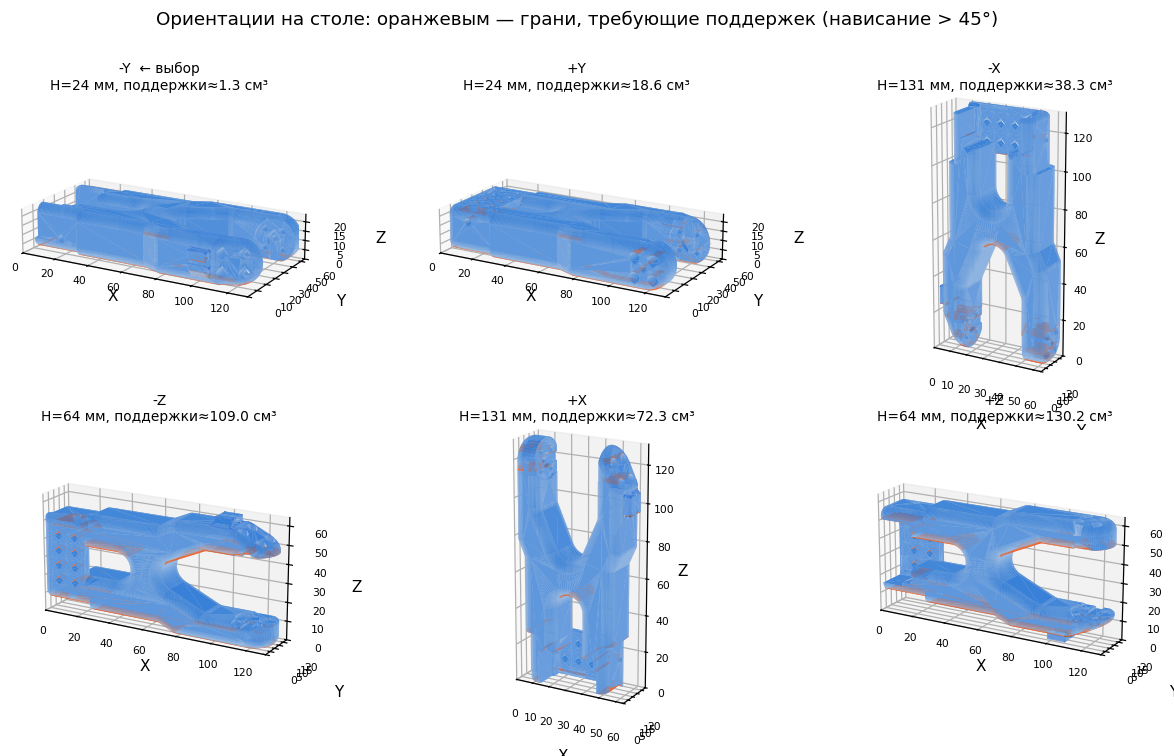

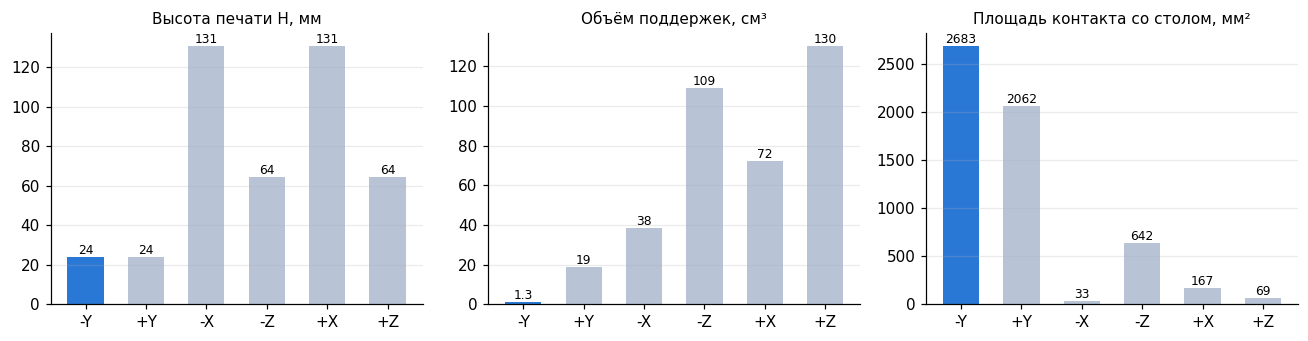

In [17]:
fig = plt.figure(figsize=(12, 6.5))
for i, key in enumerate(ori.index):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    r = ori.loc[key]
    plot_mesh(ax, oriented[key], highlight=masks[key],
              title=f"{key}{'  ← выбор' if key == best else ''}\nH={r.H_mm:.0f} мм, поддержки≈{r.support_cm3:.1f} см³")
    ax.view_init(elev=18, azim=-60)
plt.suptitle("Ориентации на столе: оранжевым — грани, требующие поддержек (нависание > 45°)", y=1.0)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, ttl in zip(axs, ["H_mm", "support_cm3", "contact_mm2"],
                        ["Высота печати H, мм", "Объём поддержек, см³", "Площадь контакта со столом, мм²"]):
    colors = [C_MODEL if k == best else "#b8c4d6" for k in ori.index]
    ax.bar(ori.index, ori[col], color=colors, width=0.6)
    ax.set_title(ttl, fontsize=10); ax.grid(axis="x", visible=False)
    for x, y in zip(ori.index, ori[col]):
        ax.text(x, y, f"{y:.0f}" if y >= 10 else f"{y:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**✍️ Что получили и что это значит.** Какая ориентация выбрана и почему? Сравните её с самой низкой и с ориентацией «как в файле» (+Z) по числу слоёв, поддержкам и контакту. Как слои будут расположены относительно основной нагрузки на деталь (анизотропия)?

*Ваш ответ:* Выбрана ориентация −Y (деталь лежит пластиной, score 0,06): H = 24 мм → N = 121 слой, контакт со столом 2683 мм² — наибольший из шести, нависания 1303 мм² и поддержки ≈1,3 см³ (1,4 % объёма детали) — наименьшие. У ближайшей альтернативы +Y те же 121 слоя, но поддержек 18,6 см³ (в 14 раз больше) и контакт 2062 мм²; у ориентации «как в файле» +Z — H = 64,4 мм, 323 слоя (в 2,7 раза больше), контакт лишь 69 мм² (в 39 раз меньше) и поддержки 130,2 см³ (в 100 раз больше, больше объёма самой детали). Стоя на торце (±X: H = 131 мм, 654 слоя) деталь ещё и недопустима по прочности: слои шли бы поперёк оси балки 130,7 мм, и изгиб отрывал бы слои друг от друга; при −Y плоскость вилки и длина балки лежат в плоскости слоёв, поэтому рабочие изгибные напряжения действуют вдоль линий экструзии, а межслойные границы нагружены только второстепенно (изгибом из плоскости пластины).

### Шаг 5. Высота слоя, число слоёв и время печати

**Зачем.** Высота слоя — главный рычаг «время ↔ качество».

**Что сделать.** Допишите две функции; таблица для h = 0,08…0,28 мм построится сама.

* **TODO-5.1 и 5.2 — `extruded_volume`** (п. 1.7): сколько пластика реально выдавит принтер. Сначала объём оболочек $V_{shell} = \min(V,\;A \cdot n_w \cdot w)$, затем добавляем заполнение: $V_{extr} = V_{shell} + \varphi\,(V - V_{shell})$.
* **TODO-5.3 — `print_time_h`** (п. 1.6): производительность $Q = 1{,}125 \cdot d \cdot h \cdot v$, мм³/с. Время $t = V/Q$ функция посчитает сама и переведёт в часы.

| Аргумент функции | Обозначение в теории |
|---|---|
| `V`, `A` | объём $V$ и площадь $A$ |
| `infill` | доля заполнения $\varphi$ (0,2 для 20 %) |
| `line_w` | ширина линии $w$ |
| `walls` | число периметров $n_w$ |
| `nozzle`, `layer`, `speed` | сопло $d$, слой $h$, скорость $v$ |

**Контрольная точка:** при уменьшении h вдвое время растёт примерно вдвое.

In [18]:
def extruded_volume(V, A, infill, line_w, walls=WALLS):
    """Объём, который выдавит принтер: оболочки + заполнение (мм³). Возвращает (V_extr, V_shell)."""
    shell = min(V, A * walls * line_w)       # TODO-5.1 ← впишите: min(V, A * walls * line_w)
    v_extr = shell + infill * (V - shell)      # TODO-5.2 ← впишите: shell + infill * (V - shell)
    check_filled("TODO-5.1–5.2, extruded_volume", {"shell": shell, "v_extr": v_extr})
    return v_extr, shell


def print_time_h(v_extr_mm3, layer, nozzle, speed):
    """Оценка времени печати снизу, ч, и производительность Q, мм³/с."""
    Q = 1.125 * nozzle * layer * speed           # TODO-5.3 ← впишите: 1.125 * nozzle * layer * speed
    check_filled("TODO-5.3, print_time_h", {"Q": Q})
    return v_extr_mm3 / Q / 3600, Q


# Готовый расчёт: время и число слоёв для шести значений высоты слоя
H = ori.loc[best, "H_mm"]
sup = ori.loc[best, "support_cm3"] * 1000
rows = []
for h in [0.08, 0.12, 0.16, 0.20, 0.24, 0.28]:
    v_ext, _ = extruded_volume(V, A, cfg["infill_pct"] / 100, cfg["line_w"])
    t, Q = print_time_h(v_ext + SUPPORT_DENSITY * sup, h, cfg["nozzle_mm"], cfg["speed"])
    rows.append(dict(layer_mm=h, layers=math.ceil(H / h), Q_mm3_s=Q, time_h=t, ok_for_nozzle=h <= 0.75 * cfg["nozzle_mm"]))
layers_df = pd.DataFrame(rows).set_index("layer_mm")
layers_df

,layers,Q_mm3_s,time_h,ok_for_nozzle
layer_mm,,,,
0.08,301,1.8,4.86,True
0.12,201,2.7,3.24,True
0.16,151,3.6,2.43,True
0.20,121,4.5,1.94,True
0.24,101,5.4,1.62,True
0.28,86,6.3,1.39,True


In [19]:
# Самопроверка шага 5 (ничего не меняйте — просто запустите)
r = layers_df.time_h
assert 1.8 < r.loc[0.12] / r.loc[0.24] < 2.2, ("Время должно быть обратно пропорционально h: "
                                               "проверьте, что в Q (TODO-5.3) входит layer")
print("Шаг 5: ок")

Шаг 5: ок


**✍️ Что получили и что это значит.** Сколько слоёв и часов при h из вашего варианта? Что вы выиграете и что потеряете при переходе на соседние значения h? Почему ваша оценка времени — нижняя граница?

*Ваш ответ:* При h = 0,20 мм из варианта: N = ⌈24/0,2⌉ = 121 слой, Q = 1,125·0,4·0,2·50 = 4,5 мм³/с, оценка времени снизу t = (31,3 см³ экструзии + 0,19 см³ поддержек)/Q ≈ 1,94 ч (в карте 1,9 ч). Переход на h = 0,16 мм даёт 151 слой и 2,43 ч (+25 % времени) взамен менее заметной «ступеньки» на пологих поверхностях; h = 0,24 мм — 101 слой и 1,62 ч (−17 % времени), но более грубая поверхность; оба значения допустимы, т.к. h ≤ 0,75·d = 0,3 мм для сопла 0,4 мм. Оценка времени — нижняя граница: Q = w·h·v предполагает непрерывную экструзию на полной скорости 50 мм/с без холостых перемещений, ретрактов, ускорений/торможений, смены слоёв и нагрева, поэтому реальная печать займёт примерно в 1,5–2 раза больше.

### Шаг 6. Масса, материал и заполнение

**Зачем.** От массы зависят расход пластика и нагрузка на сервоприводы. Сравнение материалов нужно, чтобы обоснованно выбрать или раскритиковать материал из варианта.

**Что сделать.** Масса = плотность × объём (п. 1.7). Плотность дана в г/см³, а объёмы — в мм³, поэтому в конце делим на 1000.

* **TODO-6.1** — масса для каждого материала и заполнения (по ней строится график).
* **TODO-6.2…6.4** — масса детали, поддержек и сплошной детали для **вашего** варианта.

| Переменная | Что это |
|---|---|
| `r.density_g_cm3` | плотность материала из справочника (в цикле по материалам) |
| `cfg["density"]` | плотность материала вашего варианта, г/см³ |
| `v_e`, `v_ext` | выдавленный объём детали, мм³ (оболочки + заполнение) |
| `sup` | объём поддержек при сплошном заполнении, мм³ |
| `SUPPORT_DENSITY` | плотность поддержек (0,15) |

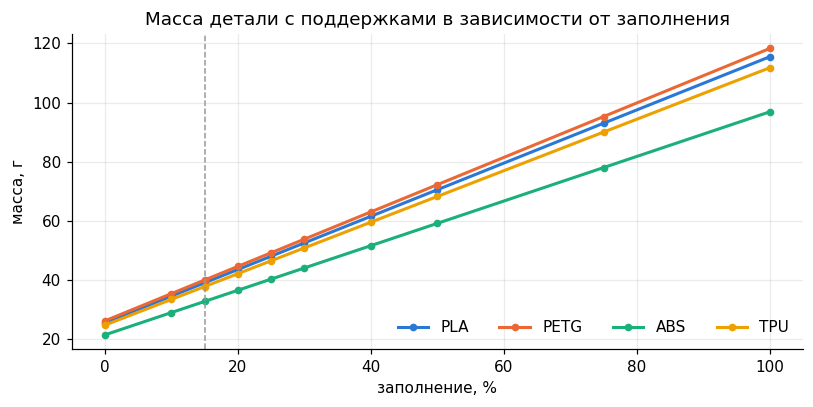

Масса: деталь 38.8 г + поддержки 0.2 г; сплошная 115.3 г


In [20]:
infills = np.array([0, 10, 15, 20, 25, 30, 40, 50, 75, 100])
rows = []
for mat, r in MATERIALS.iterrows():          # перебираем материалы…
    for f in infills:                        # …и значения заполнения
        v_e, _ = extruded_volume(V, A, f / 100, cfg["line_w"])
        mass = r.density_g_cm3 * (v_e + SUPPORT_DENSITY * sup) / 1000   # TODO-6.1 ← впишите: r.density_g_cm3 * (v_e + SUPPORT_DENSITY * sup) / 1000
        check_filled("TODO-6.1", {"mass": mass})
        rows.append(dict(material=mat, infill=f, mass_g=mass))
mass_df = pd.DataFrame(rows)

v_ext, shell = extruded_volume(V, A, cfg["infill_pct"] / 100, cfg["line_w"])
m_part = cfg["density"] * v_ext / 1000     # TODO-6.2 ← впишите: cfg["density"] * v_ext / 1000                     (масса детали, г)
m_sup = cfg["density"] * SUPPORT_DENSITY * sup / 1000      # TODO-6.3 ← впишите: cfg["density"] * SUPPORT_DENSITY * sup / 1000     (масса поддержек, г)
m_solid = cfg["density"] * V / 1000    # TODO-6.4 ← словами: плотность × полный объём V / 1000                  (сплошная деталь, г)
check_filled("TODO-6.2–6.4", {"m_part": m_part, "m_sup": m_sup, "m_solid": m_solid})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for mat, d in mass_df.groupby("material", sort=False):
    ax.plot(d.infill, d.mass_g, color=MAT_COLORS[mat], label=mat, marker="o", ms=4)
ax.axvline(cfg["infill_pct"], color="#999", lw=1, ls="--")
ax.set(title="Масса детали с поддержками в зависимости от заполнения", xlabel="заполнение, %", ylabel="масса, г")
ax.legend(frameon=False, ncol=4); plt.tight_layout(); plt.show()
print(f"Масса: деталь {m_part:.1f} г + поддержки {m_sup:.1f} г; сплошная {m_solid:.1f} г")

**✍️ Что получили и что это значит.** Какова масса детали? Насколько она меняется при удвоении заполнения? Подходит ли материал из варианта для этой детали робота (теплостойкость, жёсткость, усадка)? Если нет — что предложите?

*Ваш ответ:* Масса детали при заполнении 15 %: 38,8 г + 0,2 г поддержек = 39,0 г против 115,3 г сплошной детали — экономия материала 66 %. Удвоение заполнения (15→30 %) даёт 52,5 г, т.е. +13,5 г (+35 %), а не вдвое: оболочка 20,4 см³ (65 % выдавленных 31,3 см³) от заполнения не зависит — это согласуется с шага 3 (доля оболочек 0,22 от V, A/V = 0,24 мм⁻¹). PLA из варианта хорошо печатается и жёсток, но его теплостойкость ≈55 °C и хрупкость: under_arm — несущая балка, рядом нагруженный сервопривод STS3215 греется до 50–60 °C, возможны ползучесть и хрупкое разрушение при ударе, поэтому для рабочего плеча рекомендую PETG (теплостойкость ≈70 °C, вязкий): масса в том же режиме 40,0 г (+1,2 г), сопло 220–250 °C, стол 70–85 °C. ABS легче (32,7 г) и теплостоек, но для плоской детали длиной 131 мм без закрытой камеры рискован короблением; PLA остаётся оправданным для демонстрационных и малонагруженных режимов.

### Шаг 7. Масштаб: масса, высота и посадки

**Зачем.** Нужно проверить, можно ли напечатать деталь в масштабе s из варианта.

**Что сделать (TODO-7).** Для каждого масштаба s = 0,90…1,14 впишите четыре величины по п. 1.8 теории:

| Величина | Как меняется | Что вписать |
|---|---|---|
| высота `H_s` | $\propto s$ | высота `H` × `s` |
| объём `V_s`, см³ | $\propto s^3$ | `V * s**3 / 1000` (`**` — возведение в степень) |
| масса `m_s`, г | оболочки $\propto s^2$, заполнение $\propto s^3$ — уже учтено в `v_ext_s` | плотность × `v_ext_s` / 1000 |
| отклонение посадки `delta` | $\Delta = D\,(s-1)$ | `D * (s - 1)` |

Посадочный размер $D$ уже выбран: из `FIT_SIZE` (корпус сервопривода 24,8 мм) или наибольший габарит детали. Сравните $\Delta$ при своём s с допуском ±0,2 мм: строка `print` покажет допустимый диапазон масштаба.

In [21]:
scales = np.round(np.arange(0.90, 1.141, 0.01), 2)      # масштабы 0.90, 0.91, …, 1.14
fit_name = FIT_DIMS[cfg["fit"]]
D = FIT_SIZE.get(cfg["fit"], body.extents.max())       # посадочный размер, мм
TOL = 0.2                                               # точность FDM-принтера, мм
rows = []
for s in scales:
    v_ext_s, _ = extruded_volume(V * s**3, A * s**2, cfg["infill_pct"] / 100, cfg["line_w"])
    H_s = H * s      # TODO-7 ← впишите: H * s
    V_s = V * s**3 / 1000      #         ← впишите: V * s**3 / 1000
    m_s = cfg["density"] * v_ext_s / 1000      #         ← впишите: cfg["density"] * v_ext_s / 1000
    delta = D * (s - 1)    #         ← впишите: D * (s - 1)
    check_filled("TODO-7", {"H_s": H_s, "V_s": V_s, "m_s": m_s, "delta": delta})
    rows.append(dict(scale=s, H_mm=H_s, V_cm3=V_s, mass_g=m_s, delta_fit_mm=delta))
scale_df = pd.DataFrame(rows).set_index("scale")
print(f"Посадка сохраняется при s ∈ [{1 - TOL / D:.4f}; {1 + TOL / D:.4f}] ({fit_name}, D = {D:.1f} мм)")
print(f"При вашем s = {cfg['scale']}: Δ = {D * (cfg['scale'] - 1):+.2f} мм (допуск ±{TOL} мм)")
scale_df.loc[[0.90, 0.95, 1.00, 1.05, 1.10]]

Посадка сохраняется при s ∈ [0.9985; 1.0015] (наибольший габарит звена (межосевые расстояния в URDF), D = 130.7 мм)
При вашем s = 1.05: Δ = +6.53 мм (допуск ±0.2 мм)


,H_mm,V_cm3,mass_g,delta_fit_mm
scale,,,,
0.90,21.6,67.76,30.03,-13.07
0.95,22.8,79.69,34.24,-6.53
1.00,24.0,92.95,38.81,0.00
1.05,25.2,107.60,43.74,6.53
1.10,26.4,123.72,49.05,13.07


**✍️ Что получили и что это значит.** Чему равно $\Delta$ при s из вашего варианта? Почему масса меняется медленнее, чем $s^3$? Можно ли печатать деталь в масштабе s? Что произойдёт с моделью робота в URDF, если масштабировать звено?

*Ваш ответ:* При s = 1,05 отклонение посадки Δ = D·(s−1) = 130,7·0,05 = +6,53 мм при допуске ±0,2 мм (посадка сохраняется лишь при s ∈ [0,9985; 1,0015]) — превышение в 32 раза, печатать звено в таком масштабе нельзя. Масса растёт медленнее s³: при s = 1,05 объём увеличивается в 1,158 раза (92,95→107,60 см³), а масса — лишь в 1,127 (38,81→43,74 г), потому что объём оболочек ∝ s² (толщина n_w·w от масштаба не зависит), а как s³ растёт только заполнение. Масштабирование звена ломает и модель робота: межосевое расстояние в URDF вырастет на 6,53 мм, начала координат joint'ов и рабочая зона в симуляции перестанут соответствовать физической детали, а все отверстия и межосевые расстояния разъедутся на +5 % и не совпадут со штатными STS3215 и фурнитурой SO-101. Решение: печатать в масштабе s = 1,0 (в карте параметров поле «масштаб» должно быть 1.0, а не 1.05).

### Шаг 8. Виртуальный слайс

**Зачем.** Слайс модели плоскостями через h — это независимая проверка объёма ($V\approx\sum S_i h$). Он также показывает профиль площади слоёв и число островов: острова, которые появляются выше по детали, начинаются «в воздухе».

**Что сделать (TODO-8).** Сечения уже построены: массив `layer_area` содержит площадь каждого слоя $S_i$, мм², а `h` — высоту слоя. Объём по слоям — сумма площадей, умноженная на высоту слоя. Сумма элементов массива: `layer_area.sum()`.

**Контрольная точка:** расхождение < 1 %.

Слоёв: 120; Σ(S·h) = 92,965 мм³; mesh.volume = 92,949 мм³; расхождение 0.02 %


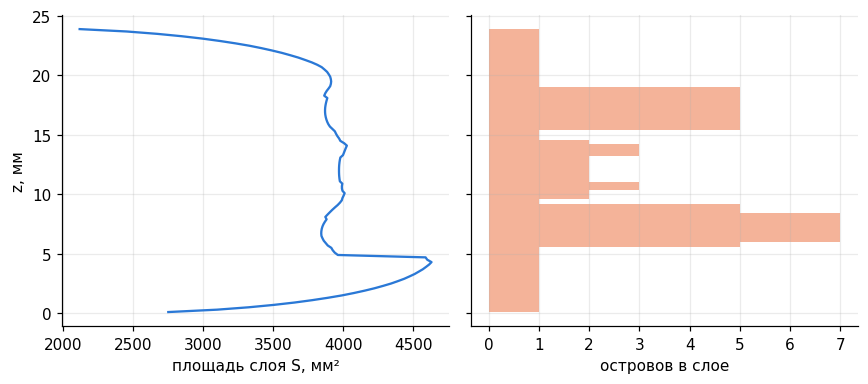

In [22]:
g = oriented[best]
h = cfg["layer_mm"]
zs = np.arange(h / 2, g.extents[2], h)
sections = g.section_multiplane(plane_origin=[0, 0, 0], plane_normal=[0, 0, 1], heights=zs)
layer_area = np.array([s.area if s is not None else 0.0 for s in sections])
islands = np.array([len(s.polygons_full) if s is not None else 0 for s in sections])
V_slices = layer_area.sum() * h    # TODO-8 ← впишите: layer_area.sum() * h
check_filled("TODO-8", {"V_slices": V_slices})
print(f"Слоёв: {len(zs)}; Σ(S·h) = {V_slices:,.0f} мм³; mesh.volume = {g.volume:,.0f} мм³; "
      f"расхождение {abs(V_slices / g.volume - 1) * 100:.2f} %")

fig, axs = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
axs[0].plot(layer_area, zs, color=C_MODEL, lw=1.5); axs[0].set(xlabel="площадь слоя S, мм²", ylabel="z, мм")
axs[1].fill_betweenx(zs, 0, islands, step="mid", color=C_WARN, alpha=0.5, lw=0); axs[1].set(xlabel="островов в слое")
plt.tight_layout(); plt.show()

In [23]:
# Самопроверка шага 8 (ничего не меняйте — просто запустите)
assert abs(V_slices / g.volume - 1) < 0.01, ("Объём по слоям должен совпадать с объёмом сетки с точностью до 1 %: "
                                             "проверьте, что сумма площадей умножена на h (TODO-8)")
print("Шаг 8: ок")

Шаг 8: ок


**✍️ Что получили и что это значит.** Насколько совпали два способа расчёта объёма и почему это важно? Где у детали «тонкие» слои и где появляются новые острова? Согласуется ли это с картинкой нависаний из шага 4?

*Ваш ответ:* Два способа расчёта объёма совпали: Σ(S·h) = 92 965 мм³ по 120 сечениям против mesh.volume = 92 949 мм³ — расхождение 0,02 %, много меньше 1 %; это независимое подтверждение, что сетка замкнута, нормали согласованы и поворот в ориентацию −Y не «потерял» объём. Профиль площади: максимум S ≈ 4600 мм² на z ≈ 4–5 мм (широкая нижняя полка со скруглёнными бобышками), «тонкие» слои — верхние (z ≈ 23–24 мм, S ≈ 2100–2700 мм²) и первый слой (S ≈ 2750 мм², что близко к контакту 2683 мм²). Новые острова (от 2 до 7 в слое) появляются в среднем поясе z ≈ 5–19 мм, где прорезь вилки разбивает сечение на отростки, а бобышки с отверстиями обособляются; выше z ≈ 19 мм сечение снова смыкается в один остров. Возникают острова над сплошной полкой, а не «в воздухе», что согласуется с шагом 4: нависания при −Y — лишь 1303 мм² скруглённых нижних поверхностей на малой высоте, поэтому и поддержки всего ≈1,3 см³.

### Шаг 9. Итоговая карта параметров печати

**Что сделать (TODO-9).** Карта — это ваши **решения** по результатам шагов 4–8. Часть полей заполнится автоматически, остальные впишите сами. Справа от каждого `...` — подсказка: готовое выражение или пример текста. Текст пишется в кавычках, например `"brim 5 мм"`.

Переменная `r` — строка таблицы ориентаций для выбранной ориентации: `r.H_mm` — высота, `r.support_cm3` — объём поддержек, `r.contact_mm2` — площадь контакта.

После запуска ячейка сохранит файл `print_map_variant_XX.csv` — его нужно загрузить в ваш репозиторий вместе с тетрадкой (в Colab: панель **Files** слева → файл → **⋮ → Download**).

In [25]:
t_h, Q = print_time_h(v_ext + SUPPORT_DENSITY * sup, cfg["layer_mm"], cfg["nozzle_mm"], cfg["speed"])
mat = MATERIALS.loc[cfg["material"]]
r = ori.loc[best]                      # показатели выбранной ориентации

# TODO-9. Вместо каждого «...» впишите своё решение (подсказка — справа)
print_map = pd.Series({
    "вариант": VARIANT,                                                    # готово
    "деталь": cfg["part"],                                                 # готово
    "масштаб": cfg["scale"],                  # ← 1.0, если по шагу 7 посадка нарушается; иначе cfg["scale"]
    "ориентация (ось вверх)": best,                                        # готово
    "габарит на столе, мм": " × ".join(f"{v:.1f}" for v in oriented[best].extents),     # ← впишите: " × ".join(f"{v:.1f}" for v in oriented[best].extents)
    "материал": cfg["material"],                 # ← cfg["material"] или другой материал в кавычках, например "PETG" (обоснуйте в выводе)
    "T сопла / стола, °C": f"{mat.t_nozzle} / {mat.t_bed}",               # готово
    "высота слоя, мм": cfg["layer_mm"],                                    # готово
    "число слоёв": math.ceil(r.H_mm / cfg["layer_mm"]),              # ← впишите: math.ceil(r.H_mm / cfg["layer_mm"])
    "периметры": WALLS,                                                    # готово
    "заполнение, %": cfg["infill_pct"],                                    # готово
    "поддержки": f"да, ≈{r.support_cm3:.1f} см³",                # ← например: f"да, ≈{r.support_cm3:.1f} см³" или "не требуются"
    "адгезия": "brim 5 мм",                  # ← например: "brim 5 мм" (ABS, малый контакт) или "без brim"
    "масса детали + поддержек, г": round(m_part + m_sup, 1),   # ← впишите: round(m_part + m_sup, 1)
    "оценка времени (снизу), ч": round(t_h, 1),     # ← впишите: round(t_h, 1)
})
check_filled("TODO-9, карта параметров", print_map.to_dict())
out = Path(f"print_map_variant_{VARIANT:02d}.csv")
print_map.to_csv(out, header=["значение"], encoding="utf-8-sig")
print_map.to_frame("карта параметров печати")

,карта параметров печати
вариант,7
деталь,under_arm_so101_v1
масштаб,1.05
ориентация (ось вверх),-Y
"габарит на столе, мм",130.7 × 64.4 × 24.0
материал,PLA
"T сопла / стола, °C",190–220 / 50–60
"высота слоя, мм",0.2
число слоёв,121
периметры,2


In [26]:
# Самопроверка шага 9 (ничего не меняйте — просто запустите)
assert not any(v is ... for v in print_map.values), "Заполните все поля карты (TODO-9)"
assert out.exists(), "Файл карты не сохранён: перезапустите ячейку выше"
print("Шаг 9: ок — файл", out, "(скачайте его: панель Files слева → файл → Download)")

Шаг 9: ок — файл print_map_variant_07.csv (скачайте его: панель Files слева → файл → Download)


### Шаг 10. Аналитический вывод

Напишите вывод по образцу структуры ниже. Каждый пункт должен содержать **ваши числа**.

1. **Модель.** Единицы, замкнутость, число тел; что пришлось исправить; $V$, $A$, габариты; ошибка «сырого» объёма.
2. **Ориентация.** Выбранная ориентация и альтернативы: H, N, поддержки, контакт; аргумент по анизотропии с учётом назначения детали.
3. **Материал и режим.** Материал, h, заполнение; масса и время; пригодность материала из варианта; что изменилось бы при другом h или заполнении.
4. **Масштаб.** $\Delta$ посадочного размера при s из варианта и решение о масштабе.
5. **Проверка и ограничения.** Совпадение объёма по слоям; какие допущения сделаны в расчёте времени, поддержек и прочности.

*Ваш вывод:*
1. **Модель.** STL хранился в метрах (наибольший габарит 0,1307 < 1) — координаты умножены на 1000; получено одно замкнутое тело (is_watertight = True, shells = 1), F = 39 516 граней, габариты 130,7 × 24,0 × 64,4 мм, A = 226,86 см², V = 92,95 см³. Исправлять, кроме единиц, ничего не пришлось: полостей и мусорных тел нет, ошибка «сырого» объёма +0,0 %. χ = −38 → род 20 (крепёжные отверстия и окна облегчения).
2. **Ориентация.** Выбрана −Y: H = 24 мм, N = 121 слой, контакт 2683 мм², нависания 1303 мм², поддержки 1,3 см³, score 0,06. Альтернативы хуже: +Y — 18,6 см³ поддержек при том же N; «как в файле» +Z — 323 слоя, контакт 69 мм², поддержки 130,2 см³; ±X — 654 слоя и слои поперёк балки. При −Y плоскость вилки (плоскость рабочего изгиба) лежит в плоскости слоёв: изгибные напряжения вдоль балки 130,7 мм несут нити внутри слоя, а межслойные связи нагружены только изгибом из плоскости пластины.
3. **Материал и режим.** PLA, h = 0,20 мм (121 слой), 2 периметра, заполнение 15 %: V_extr = 31,3 см³ (из них оболочки 20,4 см³), масса 38,8 + 0,2 = 39,0 г, время снизу 1,9 ч при Q = 4,5 мм³/с; сплошная деталь весила бы 115,3 г. При h = 0,16 мм время 2,4 ч и чище поверхность, при h = 0,24 мм — 1,6 ч и грубее «ступенька»; заполнение 30 % дало бы 52,5 г (+35 %), т.е. массой управляют периметры, а не заполнение. PLA приемлем для учебной/лёгкой нагрузки, но теплостойкость 55 °C и хрупкость рядом с греющимся сервоприводом — ограничение; для рабочего плеча рекомендую PETG (40,0 г в том же режиме, теплостойкость 70 °C).
4. **Масштаб.** При s = 1,05 Δ = 130,7·0,05 = +6,53 мм при допуске ±0,2 мм (допустимо s ∈ [0,9985; 1,0015]) — масштабирование недопустимо, печать в s = 1,0; в URDF такое звено сместило бы оси joint'ов на 6,5 мм и раздвинуло все посадочные отверстия на +5 %, сломав соответствие симуляции и реальности. Масса при s = 1,05 была бы 43,7 г (+12,7 %) при росте объёма на 15,8 %, поскольку оболочки растут как s².
5. **Проверка и ограничения.** Виртуальный слайс (120 сечений) дал Σ(S·h) = 92 965 мм³ против 92 949 мм³ у сетки (расхождение 0,02 % < 1 %) — объёму и выбранной ориентации можно доверять. Ограничения модели расчёта: время — оценка снизу без холостых перемещений, ускорений и смены слоёв (реально ≈ в 1,5–2 раза дольше); поддержки оценены грубой формулой ΣA·|nz|·z с плотностью 0,15 без мостов и интерфейсных слоёв; прочность и анизотропия учтены качественно, без расчёта напряжений; плотности материалов и скорости — паспортные учебные; масса brim и первого слоя не учтена.